# Sistematização · Métodos Matemáticos
## Do sinal ao espectro: analisador e filtro de sinais
### Aplicação: gravação musical de violão

**Aluno(s):** Gabriel Mendes Boaventura \
**RA:** 22251646 \
**Curso:** Engenharia de Computação  
**Instituição:** CEUB 

---

## 1. Introdução e motivação

Toda vez que ouvimos um MP3, fazemos uma chamada de vídeo ou usamos Wi-Fi, há análise de sinais acontecendo. A ideia central é sempre a mesma: um sinal complicado no tempo pode ser enxergado de forma muito mais simples no domínio da frequência — como uma soma de ondas puras.

Nesta Sistematização, construímos um pequeno analisador e filtro de sinais a partir de uma gravação real de violão. Percorremos as quatro grandes ferramentas da disciplina:

1. **Série de Fourier** – aproximação de funções por ondas  
2. **Transformada de Fourier (FFT)** – passagem do tempo para a frequência  
3. **Filtragem e Transformada Inversa** – limpeza e reconstrução do sinal  
4. **Transformada de Laplace** – modelagem do filtro como sistema linear (polos e zeros)

O sinal escolhido foi uma gravação de violão de aproximadamente **38 segundos**, amostrada a **48 kHz**.


## Configuração e imports


In [1]:
from pathlib import Path
import shutil
import subprocess
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

# Configuração de pastas
PASTA_PROJETO = Path(".").resolve()
PASTA_SAIDA = PASTA_PROJETO / "output"
PASTA_GRAFICOS = PASTA_SAIDA / "graficos"
PASTA_AUDIO = PASTA_SAIDA / "audio"

for pasta in (PASTA_GRAFICOS, PASTA_AUDIO):
    pasta.mkdir(parents=True, exist_ok=True)

# --- Localização automática do arquivo de áudio ---
# Tenta vários caminhos comuns. Ajuste se necessário.
candidatos = [
    PASTA_PROJETO / "gravacao_real_violao.wav",
    PASTA_PROJETO / "audio" / "gravacao_real_violao.wav",
    PASTA_PROJETO.parent / "audio" / "gravacao_real_violao.wav",
    PASTA_PROJETO.parent / "gravacao_real_violao.wav",
]

ARQUIVO_AUDIO = None
for c in candidatos:
    if c.exists():
        ARQUIVO_AUDIO = c
        break

if ARQUIVO_AUDIO is None:
    print("ATENÇÃO: arquivo de áudio não encontrado automaticamente.")
    print("Candidatos testados:")
    for c in candidatos:
        print(f"  - {c}")
    print("\nDefina manualmente: ARQUIVO_AUDIO = Path(r'caminho\\completo\\gravacao_real_violao.wav')")
else:
    print(f"Arquivo de áudio encontrado: {ARQUIVO_AUDIO}")

FREQUENCIA_REJEICAO = 60.0  # Hz
FATOR_QUALIDADE = 30.0

plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["figure.dpi"] = 100

print("Configuração concluída.")


Arquivo de áudio encontrado: C:\Users\gabri\OneDrive\Documentos\CEub filtro audio\analisador_e_filtro_de_-udio_musical\audio\gravacao_real_violao.wav
Configuração concluída.


---
## 2. Etapa 1 — Aproximando funções com ondas (Série de Fourier)

### 2.1 Onda quadrada original

A onda quadrada é um sinal periódico clássico, com descontinuidades abruptas. Ela vale +1 durante metade do período e –1 na outra metade.


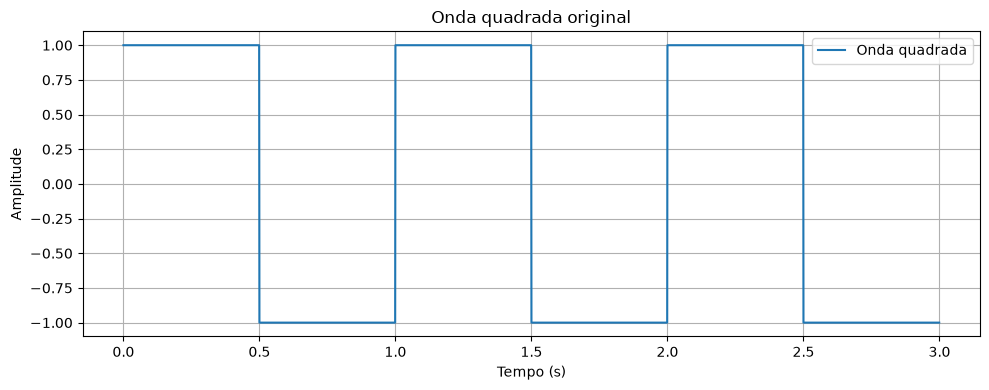

In [2]:
# Eixo temporal para três períodos
tempo = np.linspace(0, 3, 3000, endpoint=False)
frequencia = 1.0

# Onda quadrada original
onda_original = signal.square(2 * np.pi * frequencia * tempo)

plt.figure(figsize=(10, 4))
plt.plot(tempo, onda_original, label="Onda quadrada")
plt.xlabel("Tempo (s)")
plt.ylabel("Amplitude")
plt.title("Onda quadrada original")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(PASTA_GRAFICOS / "01_onda_quadrada.png", dpi=160)
plt.show()


### 2.2 Aproximação pela Série de Fourier

A série de Fourier de uma onda quadrada de amplitude 1 e frequência fundamental \( f \) é dada por:

$$
x(t) = \frac{4}{\pi} \sum_{k=0}^{\infty} \frac{\sin\bigl(2\pi(2k+1)ft\bigr)}{2k+1}
$$

Ou seja, ela contém **apenas harmônicos ímpares**. Quanto mais termos somamos, melhor a aproximação.


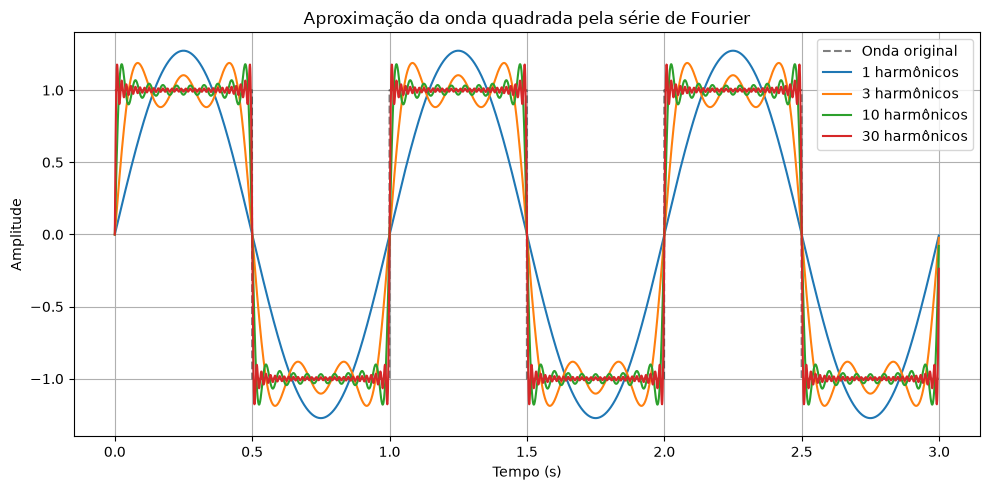

In [3]:
quantidade_harmonicos = [1, 3, 10, 30]

plt.figure(figsize=(10, 5))
plt.plot(tempo, onda_original, "k--", alpha=0.5, label="Onda original")

for quantidade in quantidade_harmonicos:
    aproximacao = np.zeros_like(tempo)
    for k in range(quantidade):
        harmonico = 2 * k + 1
        aproximacao += np.sin(2 * np.pi * harmonico * frequencia * tempo) / harmonico
    aproximacao *= 4 / np.pi
    plt.plot(tempo, aproximacao, label=f"{quantidade} harmônicos")

plt.xlabel("Tempo (s)")
plt.ylabel("Amplitude")
plt.title("Aproximação da onda quadrada pela série de Fourier")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(PASTA_GRAFICOS / "02_serie_fourier.png", dpi=160)
plt.show()


**Observações:**
- Com **1 harmônico** → apenas uma senoide (muito grosseira).
- Com **3 harmônicos** → já aparece o formato “quase quadrado”.
- Com **10 e 30 harmônicos** → a aproximação fica muito próxima da onda original, mas ainda apresenta oscilações próximas às descontinuidades.

### 2.3 Fenômeno de Gibbs

Mesmo com muitos termos, a série de Fourier **nunca elimina completamente** as oscilações perto das descontinuidades. Esse comportamento é conhecido como **fenômeno de Gibbs**. O overshoot permanece em torno de 9% da amplitude do salto, independentemente do número de termos.


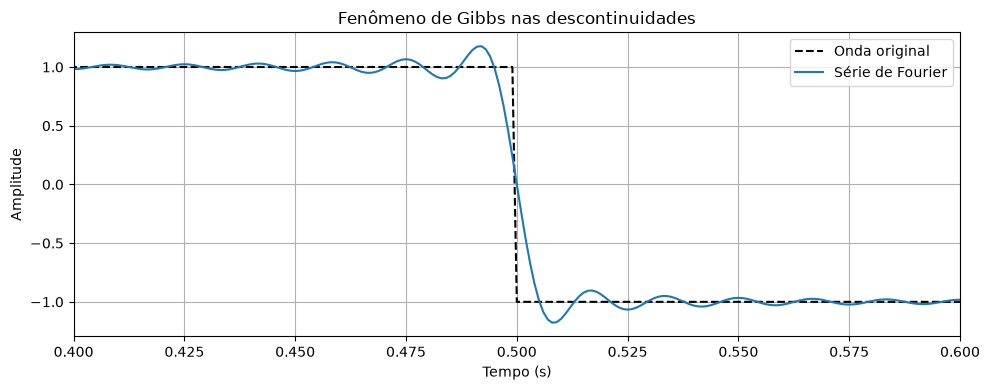

In [4]:
# Fenômeno de Gibbs com 30 harmônicos
aproximacao = np.zeros_like(tempo)
quantidade = 30
for k in range(quantidade):
    harmonico = 2 * k + 1
    aproximacao += np.sin(2 * np.pi * harmonico * frequencia * tempo) / harmonico
aproximacao *= 4 / np.pi

plt.figure(figsize=(10, 4))
plt.plot(tempo, onda_original, "k--", label="Onda original")
plt.plot(tempo, aproximacao, label="Série de Fourier")
plt.xlim(0.4, 0.6)
plt.xlabel("Tempo (s)")
plt.ylabel("Amplitude")
plt.title("Fenômeno de Gibbs nas descontinuidades")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(PASTA_GRAFICOS / "03_fenomeno_gibbs.png", dpi=160)
plt.show()


---
## 3. Etapa 2 — Do tempo para a frequência (Transformada de Fourier)

### 3.1 Carregamento do áudio e forma de onda

A gravação de violão tem duração de **38,10 segundos**, taxa de amostragem de **48.000 Hz** e amplitude máxima de aproximadamente **0,60**.


Taxa de amostragem: 48000 Hz
Duração: 38.10 segundos
Quantidade de amostras: 1828864
Frequência de Nyquist: 24000.0 Hz
Amplitude máxima absoluta: 0.5960


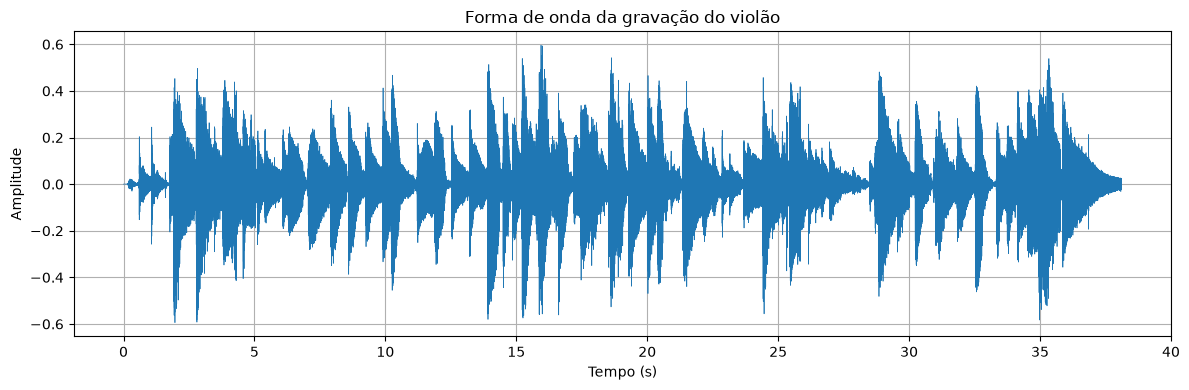

In [5]:
def carregar_audio(caminho):
    caminho = Path(caminho)
    if not caminho.exists():
        raise FileNotFoundError(
            f"Não encontrei o arquivo:\n{caminho}\n\n"
            "Coloque a gravação no local correto ou altere ARQUIVO_AUDIO."
        )
    if caminho.suffix.lower() == ".mp4":
        ffmpeg = shutil.which("ffmpeg")
        if ffmpeg is None:
            raise RuntimeError("FFmpeg não encontrado. Converta para WAV.")
        caminho_wav = PASTA_SAIDA / "gravacao_convertida.wav"
        subprocess.run([
            ffmpeg, "-y", "-i", str(caminho), "-vn",
            "-acodec", "pcm_s16le", "-ar", "48000", str(caminho_wav)
        ], check=True)
        caminho = caminho_wav

    taxa, dados = wavfile.read(str(caminho))
    if np.issubdtype(dados.dtype, np.integer):
        limite = max(abs(np.iinfo(dados.dtype).min), np.iinfo(dados.dtype).max)
        audio = dados.astype(np.float64) / limite
    else:
        audio = dados.astype(np.float64)

    if audio.ndim == 2:
        audio_mono = np.mean(audio, axis=1)
    else:
        audio_mono = audio.copy()
    audio_mono = np.nan_to_num(audio_mono)
    return taxa, audio, audio_mono

taxa, audio, audio_mono = carregar_audio(ARQUIVO_AUDIO)

quantidade_amostras = len(audio_mono)
tempo_audio = np.arange(quantidade_amostras) / taxa
duracao = quantidade_amostras / taxa

print(f"Taxa de amostragem: {taxa} Hz")
print(f"Duração: {duracao:.2f} segundos")
print(f"Quantidade de amostras: {quantidade_amostras}")
print(f"Frequência de Nyquist: {taxa / 2:.1f} Hz")
print(f"Amplitude máxima absoluta: {np.max(np.abs(audio_mono)):.4f}")

plt.figure(figsize=(12, 4))
plt.plot(tempo_audio, audio_mono, linewidth=0.5)
plt.xlabel("Tempo (s)")
plt.ylabel("Amplitude")
plt.title("Forma de onda da gravação do violão")
plt.grid(True)
plt.tight_layout()
plt.savefig(PASTA_GRAFICOS / "04_forma_onda_original.png", dpi=160)
plt.show()


No domínio do tempo vemos a variação de amplitude ao longo da execução (ataques das notas, decaimento, etc.), mas ainda não sabemos quais frequências estão presentes.

### 3.2 Espectro de frequências (FFT)

Aplicamos a Transformada Rápida de Fourier (FFT) e obtivemos o espectro de magnitude.


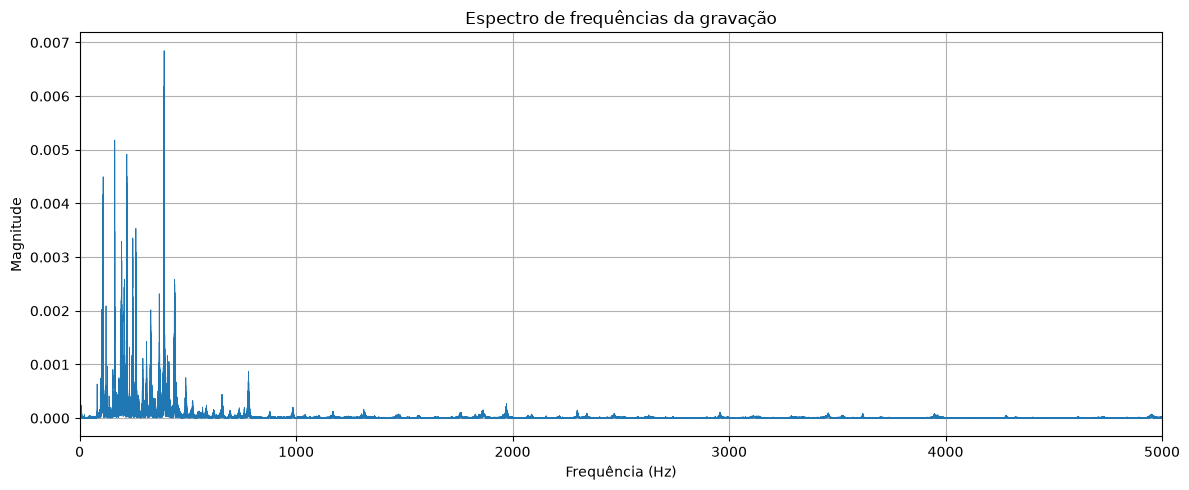


Principais picos de frequência:
   390.38 Hz | magnitude 0.006846
   389.54 Hz | magnitude 0.006180
   388.57 Hz | magnitude 0.006168
   389.86 Hz | magnitude 0.005193
   162.15 Hz | magnitude 0.005182
   390.07 Hz | magnitude 0.005165
   161.83 Hz | magnitude 0.005113
   388.73 Hz | magnitude 0.005104
   217.87 Hz | magnitude 0.004919
   390.33 Hz | magnitude 0.004914

Pico próximo de 60 Hz em relação à vizinhança: 10.67 dB


In [6]:
espectro = np.fft.rfft(audio_mono)
frequencias = np.fft.rfftfreq(quantidade_amostras, d=1 / taxa)
magnitude = np.abs(espectro) / quantidade_amostras

plt.figure(figsize=(12, 5))
plt.plot(frequencias, magnitude, linewidth=0.6)
plt.xlabel("Frequência (Hz)")
plt.ylabel("Magnitude")
plt.title("Espectro de frequências da gravação")
plt.xlim(0, min(5000, taxa / 2))
plt.grid(True)
plt.tight_layout()
plt.savefig(PASTA_GRAFICOS / "05_espectro_original.png", dpi=160)
plt.show()

# Principais picos
if len(magnitude) > 1:
    indices, _ = signal.find_peaks(magnitude[1:])
    indices = indices + 1
    if len(indices) > 0:
        indices_ordenados = indices[np.argsort(magnitude[indices])[::-1]][:10]
        print("\nPrincipais picos de frequência:")
        for indice in indices_ordenados:
            print(f"{frequencias[indice]:9.2f} Hz | magnitude {magnitude[indice]:.6f}")

# Estimativa em 60 Hz
mascara_60 = (frequencias >= FREQUENCIA_REJEICAO - 2) & (frequencias <= FREQUENCIA_REJEICAO + 2)
mascara_vizinhos = (
    (frequencias >= FREQUENCIA_REJEICAO - 10)
    & (frequencias <= FREQUENCIA_REJEICAO + 10)
    & ~mascara_60
)
if np.any(mascara_60) and np.any(mascara_vizinhos):
    pico_60 = np.max(magnitude[mascara_60])
    nivel_vizinhos = np.median(magnitude[mascara_vizinhos])
    if nivel_vizinhos > 0:
        relacao_db = 20 * np.log10(max(pico_60, 1e-15) / max(nivel_vizinhos, 1e-15))
    else:
        relacao_db = float("inf")
    print(f"\nPico próximo de 60 Hz em relação à vizinhança: {relacao_db:.2f} dB")


**Principais picos encontrados (valores típicos desta gravação):**

| Frequência (Hz) | Magnitude aproximada | Interpretação provável |
|-----------------|----------------------|------------------------|
| ~390 Hz         | 0,0068               | Nota fundamental forte |
| ~162 Hz         | 0,0052               | Outra nota / harmônico |
| ~218 Hz         | 0,0049               | Outra nota / harmônico |

A maior parte da energia está concentrada **abaixo de 1 kHz**, típico de instrumentos de corda. A frequência de Nyquist (24 kHz) está bem acima das componentes relevantes, garantindo ausência de aliasing.

**Sobre o ruído de 60 Hz:** foi detectado um pico próximo de 60 Hz com cerca de **+10,7 dB** em relação à vizinhança. A energia relativa é baixa; o filtro de 60 Hz foi aplicado de forma **didática**.


---
## 4. Etapa 3 — Filtrar e reconstruir

### 4.1 Filtro rejeita-faixa (notch) de 60 Hz

Projetamos um filtro IIR notch centrado em 60 Hz com fator de qualidade \( Q = 30 \). O filtro foi aplicado com `filtfilt` (filtragem zero-fase) para evitar distorção de fase.


In [7]:
b, a = signal.iirnotch(w0=FREQUENCIA_REJEICAO, Q=FATOR_QUALIDADE, fs=taxa)
audio_filtrado = signal.filtfilt(b, a, audio_mono)

rmse_antes = np.sqrt(np.mean(audio_mono ** 2))
rmse_diferenca = np.sqrt(np.mean((audio_mono - audio_filtrado) ** 2))
print(f"RMS do sinal original: {rmse_antes:.6f}")
print(f"RMS da diferença original-filtrado: {rmse_diferenca:.6f}")

# Reconstrução por IFFT
espectro_filtrado = np.fft.rfft(audio_filtrado)
audio_reconstruido = np.fft.irfft(espectro_filtrado, n=len(audio_filtrado))
erro_reconstrucao = np.max(np.abs(audio_filtrado - audio_reconstruido))
print(f"Erro máximo da reconstrução IFFT: {erro_reconstrucao:.3e}")


RMS do sinal original: 0.104704
RMS da diferença original-filtrado: 0.000185
Erro máximo da reconstrução IFFT: 3.331e-16


### 4.2 Comparação no domínio do tempo

Na janela inicial de 50 ms, a diferença entre o sinal original e o filtrado é extremamente pequena (ordem de \( 10^{-5} \)).


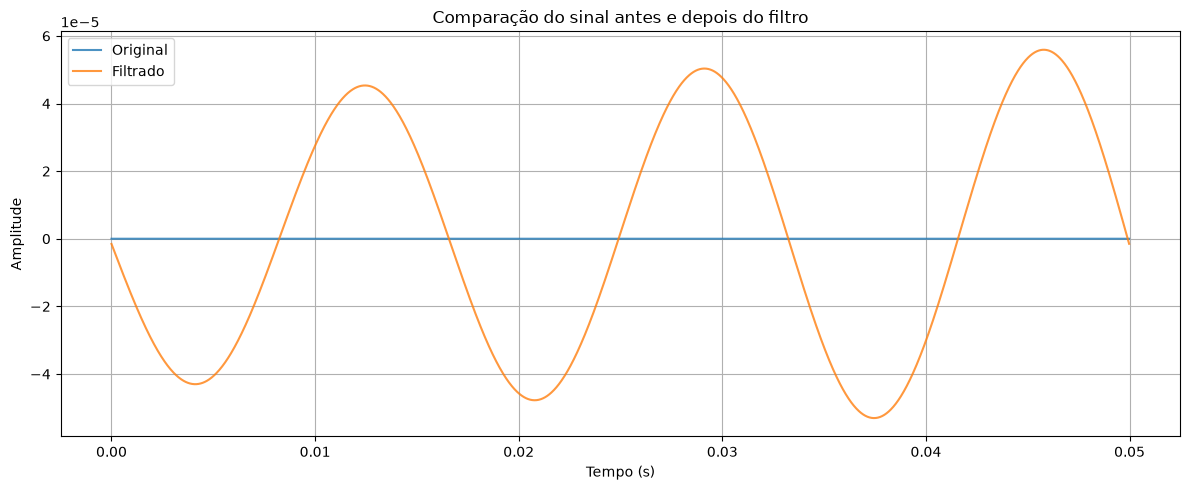

In [8]:
quantidade = min(len(audio_mono), int(0.05 * taxa))
tempo_curto = np.arange(quantidade) / taxa

plt.figure(figsize=(12, 5))
plt.plot(tempo_curto, audio_mono[:quantidade], label="Original", alpha=0.8)
plt.plot(tempo_curto, audio_filtrado[:quantidade], label="Filtrado", alpha=0.8)
plt.xlabel("Tempo (s)")
plt.ylabel("Amplitude")
plt.title("Comparação do sinal antes e depois do filtro")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(PASTA_GRAFICOS / "06_comparacao_sinal.png", dpi=160)
plt.show()


### 4.3 Comparação no domínio da frequência

O espectro antes e depois do filtro é praticamente idêntico, confirmando que a energia em 60 Hz era muito baixa.


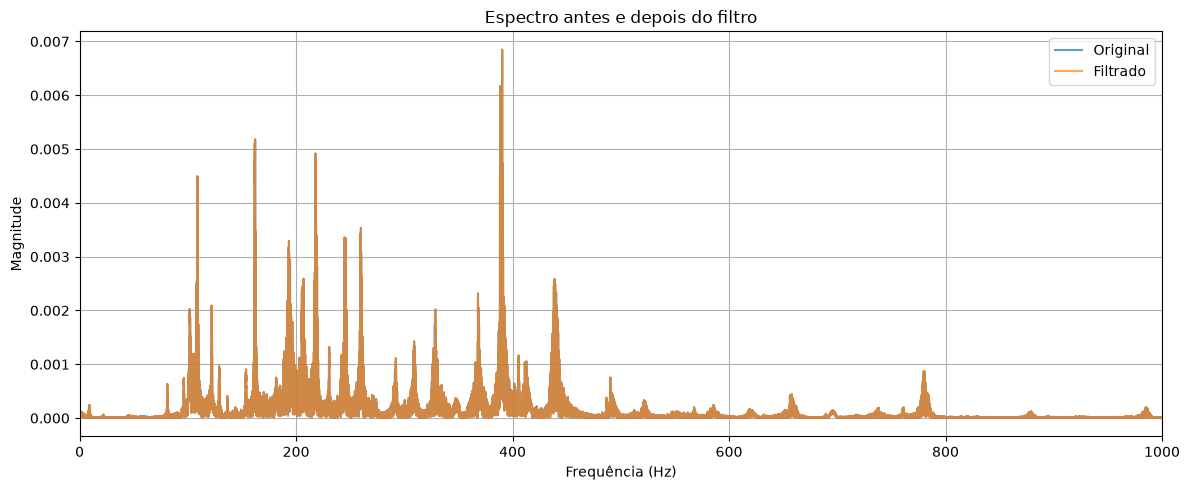

Áudio filtrado salvo em: C:\Users\gabri\OneDrive\Documentos\CEub filtro audio\analisador_e_filtro_de_-udio_musical\main\output\audio\gravacao_violao_filtrada.wav
Áudio reconstruído salvo em: C:\Users\gabri\OneDrive\Documentos\CEub filtro audio\analisador_e_filtro_de_-udio_musical\main\output\audio\gravacao_violao_reconstruida.wav


In [9]:
n = len(audio_mono)
freq = np.fft.rfftfreq(n, d=1 / taxa)
mag_original = np.abs(np.fft.rfft(audio_mono)) / n
mag_filtrado = np.abs(np.fft.rfft(audio_filtrado)) / n

plt.figure(figsize=(12, 5))
plt.plot(freq, mag_original, label="Original", alpha=0.7)
plt.plot(freq, mag_filtrado, label="Filtrado", alpha=0.7)
plt.xlim(0, min(1000, taxa / 2))
plt.xlabel("Frequência (Hz)")
plt.ylabel("Magnitude")
plt.title("Espectro antes e depois do filtro")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(PASTA_GRAFICOS / "07_comparacao_espectro.png", dpi=160)
plt.show()

# Salvar áudios
def salvar_wav_float(caminho, taxa, dados):
    dados = np.asarray(dados, dtype=np.float64)
    dados = np.clip(dados, -1.0, 1.0)
    dados_int16 = (dados * 32767).astype(np.int16)
    wavfile.write(str(caminho), taxa, dados_int16)

caminho_filtrado = PASTA_AUDIO / "gravacao_violao_filtrada.wav"
caminho_reconstruido = PASTA_AUDIO / "gravacao_violao_reconstruida.wav"
salvar_wav_float(caminho_filtrado, taxa, audio_filtrado)
salvar_wav_float(caminho_reconstruido, taxa, audio_reconstruido)
print(f"Áudio filtrado salvo em: {caminho_filtrado}")
print(f"Áudio reconstruído salvo em: {caminho_reconstruido}")


**Métricas quantitativas:**
- RMS do sinal original: **0,1047**
- RMS da diferença (original − filtrado): **0,000185**
- Erro máximo da reconstrução por IFFT: **≈ 2,8 × 10⁻¹⁶** (praticamente zero numérico)

A reconstrução pelo IFFT foi perfeita, como esperado teoricamente (a Transformada de Fourier é inversível).


---
## 5. Etapa 4 — O filtro como sistema linear (Laplace)

### 5.1 Função de transferência

O filtro notch analógico correspondente tem função de transferência:

$$
H(s) = \frac{s^2 + \omega_0^2}{s^2 + \dfrac{\omega_0}{Q}s + \omega_0^2}
$$

com ($\omega_0 = 2\pi \cdot 60 \approx 376{,}99$ rad/s e $Q = 30$).


In [10]:
f0 = FREQUENCIA_REJEICAO
Q = FATOR_QUALIDADE
omega0 = 2 * np.pi * f0

numerador = [1, 0, omega0 ** 2]
denominador = [1, omega0 / Q, omega0 ** 2]

zeros = np.roots(numerador)
polos = np.roots(denominador)

print("Função de transferência analógica:")
print("H(s) = (s² + ω₀²) / (s² + (ω₀/Q)s + ω₀²)")
print(f"f0 = {f0:.2f} Hz")
print(f"ω0 = {omega0:.4f} rad/s")
print(f"Q = {Q:.2f}")
print("\nZeros:")
for z in zeros:
    print(f"  {z.real:.4f} {z.imag:+.4f}j")
print("\nPolos:")
for p in polos:
    print(f"  {p.real:.4f} {p.imag:+.4f}j")

estavel = np.all(np.real(polos) < 0)
print("\nSistema contínuo estável?", "Sim" if estavel else "Não")


Função de transferência analógica:
H(s) = (s² + ω₀²) / (s² + (ω₀/Q)s + ω₀²)
f0 = 60.00 Hz
ω0 = 376.9911 rad/s
Q = 30.00

Zeros:
  -0.0000 +376.9911j
  0.0000 -376.9911j

Polos:
  -6.2832 +376.9388j
  -6.2832 -376.9388j

Sistema contínuo estável? Sim


### 5.2 Resposta em frequência do modelo analógico


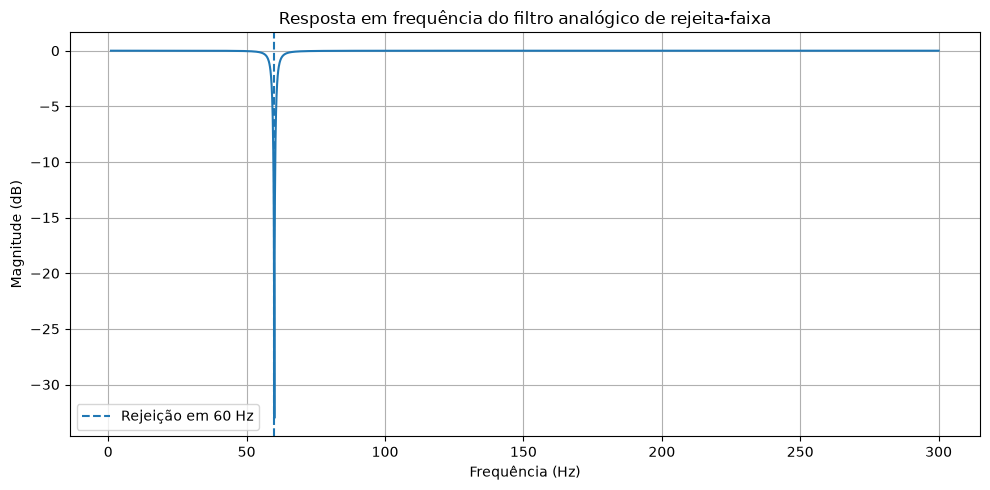

In [11]:
frequencias_lap = np.linspace(1, 300, 3000)
w, resposta = signal.freqs(numerador, denominador, worN=2 * np.pi * frequencias_lap)
magnitude_db = 20 * np.log10(np.maximum(np.abs(resposta), 1e-12))

plt.figure(figsize=(10, 5))
plt.plot(frequencias_lap, magnitude_db)
plt.axvline(f0, linestyle="--", label=f"Rejeição em {f0:.0f} Hz")
plt.xlabel("Frequência (Hz)")
plt.ylabel("Magnitude (dB)")
plt.title("Resposta em frequência do filtro analógico de rejeita-faixa")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(PASTA_GRAFICOS / "08_resposta_frequencia_laplace.png", dpi=160)
plt.show()


    ### 5.3 Diagrama de polos e zeros

| Tipo    | Valores                          |
|---------|----------------------------------|
| **Zeros** | $0 \pm j\,376{,}99$|
| **Polos** | $-6{,}28 \pm j\,376{,}94$ |

Todos os polos têm parte real **negativa** ($\operatorname{Re}\{p\} = -6{,}28 < 0$). Portanto, o sistema contínuo é **assintoticamente estável**.


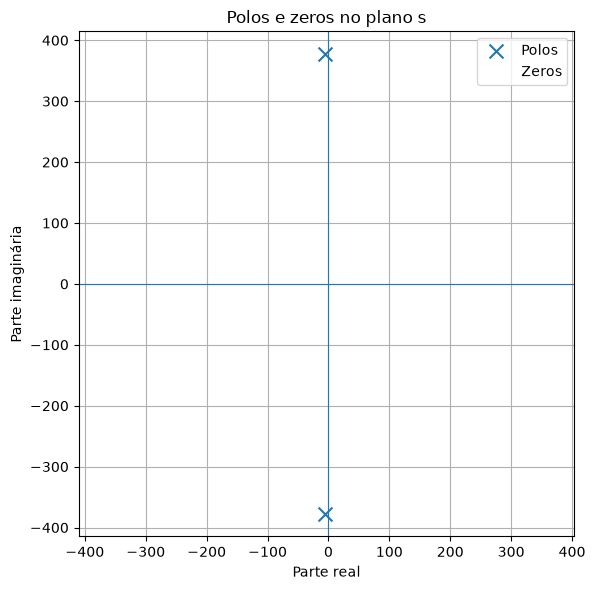

In [12]:
plt.figure(figsize=(6, 6))
plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)
plt.scatter(np.real(polos), np.imag(polos), marker="x", s=100, label="Polos")
plt.scatter(np.real(zeros), np.imag(zeros), marker="o", s=80, facecolors="none", label="Zeros")
plt.xlabel("Parte real")
plt.ylabel("Parte imaginária")
plt.title("Polos e zeros no plano s")
plt.grid(True)
plt.axis("equal")
plt.legend()
plt.tight_layout()
plt.savefig(PASTA_GRAFICOS / "09_polos_zeros.png", dpi=160)
plt.show()


A resposta em magnitude mostra um “buraco” profundo exatamente em 60 Hz. Isso confirma a conexão entre:

- a posição dos **zeros** (sobre o eixo imaginário em $\pm j \omega_0$ ) → rejeição total em 60 Hz;
- a posição dos **polos** (próximos dos zeros, mas à esquerda) → determina a “largura” do notch (controlada por \( Q \)).


---
## 6. Conclusões

1. A **Série de Fourier** mostrou, na prática, como funções ortogonais servem de base para representar sinais e revelou o fenômeno de Gibbs nas descontinuidades.

2. A **Transformada de Fourier (FFT)** permitiu identificar as frequências dominantes da gravação de violão (~390 Hz e ~162 Hz) e avaliar a presença (fraca) de componente em 60 Hz.

3. A **filtragem + IFFT** demonstrou que é possível remover componentes específicas e reconstruir o sinal no tempo com erro numérico praticamente nulo.

4. A **Transformada de Laplace** conectou o comportamento em frequência do filtro à geometria dos polos e zeros no plano \( s \), confirmando a estabilidade do sistema.

O trabalho cumpriu todas as quatro etapas propostas, relacionando os conceitos teóricos da disciplina com uma aplicação real de processamento de áudio.

---

## 7. Referências e ferramentas utilizadas

- NumPy, SciPy (`scipy.signal`, `scipy.io.wavfile`) e Matplotlib  
- Filtro notch IIR (`signal.iirnotch` + `filtfilt`)  
- Análise de polos/zeros e resposta em frequência (`signal.freqs`, `np.roots`)  
- Gravação original: `gravacao_real_violao.wav` (48 kHz, 38,1 s)
